# Assignment 1 — Bangla Sentiment Classification with LSTM

In [10]:
import os, re, random, copy, json
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| PyTorch:', torch.__version__)

Device: cuda | PyTorch: 2.13.0+cu130


## 1. Load the genuine Bangla dataset

In [11]:
from urllib.request import urlretrieve
ROOT = Path('.')
BASE = 'https://huggingface.co/datasets/khondoker/SentNoB/resolve/main/'
for filename in ('Train.csv', 'Val.csv', 'Test.csv'):
    local = ROOT / filename
    if not local.exists():
        try:
            urlretrieve(BASE + filename, local)
        except Exception as exc:
            raise RuntimeError(f'Cannot download {filename}. Upload it to the notebook directory and rerun.') from exc

train_df = pd.read_csv('Train.csv')[['Data','Label']].dropna().copy()
val_df = pd.read_csv('Val.csv')[['Data','Label']].dropna().copy()
test_df = pd.read_csv('Test.csv')[['Data','Label']].dropna().copy()
for frame in (train_df, val_df, test_df):
    frame['Label'] = frame['Label'].astype(int)
    assert frame['Label'].isin([0,1,2]).all()
print('Train:', len(train_df), '| Validation:', len(val_df), '| Test:', len(test_df))
print('Class names:', {0:'Neutral', 1:'Positive', 2:'Negative'})
display(train_df.head(5))
print('Train label counts:')
print(train_df['Label'].value_counts().sort_index())

Train: 12575 | Validation: 1567 | Test: 1586
Class names: {0: 'Neutral', 1: 'Positive', 2: 'Negative'}


,Data,Label
0,মুগ্ধ হয়ে গেলাম মামু. আর তোমায় কি কমু. বলো তোম...,1
1,এই কুত্তার বাচ্চাদের জন্য দেশটা আজ এমন অবস্তায়...,2
2,ভাই আপনার কথাই যাদু রয়েছে,1
3,উওরটা আমার অনেক ভাল লেগেছে,1
4,আমার নিজের গাড়ী নিয়ে কি সাজেক যেতে পারবো না ?...,0


Train label counts:
Label
0    2894
1    5133
2    4548
Name: count, dtype: int64


## 2. Clean, tokenize and pad text

In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^\u0980-\u09ffa-z0-9\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def tokenize(text):
    return clean_text(text).split()

for df in (train_df,val_df,test_df):
    df['clean'] = df['Data'].map(clean_text)
    df.drop(df[df.clean.eq('')].index, inplace=True)

counter = Counter(token for line in train_df['clean'] for token in tokenize(line))
MAX_VOCAB, MAX_LEN = 15000, 60
vocab = {'<PAD>': 0, '<UNK>': 1}
for token, _ in counter.most_common(MAX_VOCAB-2):
    vocab[token] = len(vocab)

def encode(text):
    ids = [vocab.get(w,1) for w in tokenize(text)[:MAX_LEN]]
    return ids or [1]

class BanglaDataset(Dataset):
    def __init__(self, df): self.data=list(zip(df['clean'].tolist(),df['Label'].tolist()))
    def __len__(self): return len(self.data)
    def __getitem__(self,i):
        text,label = self.data[i]
        return torch.tensor(encode(text),dtype=torch.long),int(label)

def collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in sequences],dtype=torch.long)
    padded = pad_sequence(sequences,batch_first=True,padding_value=0)
    return padded,lengths,torch.tensor(labels,dtype=torch.long)

train_loader=DataLoader(BanglaDataset(train_df),batch_size=128,shuffle=True,collate_fn=collate)
val_loader=DataLoader(BanglaDataset(val_df),batch_size=256,shuffle=False,collate_fn=collate)
test_loader=DataLoader(BanglaDataset(test_df),batch_size=256,shuffle=False,collate_fn=collate)
example = tokenize(train_df['Data'].iloc[0])[:15]
print('Tokens:', example)
print('IDs:', encode(train_df['Data'].iloc[0])[:15])
print('Vocabulary:',len(vocab),'| Maximum sequence length:',MAX_LEN)
ids, lengths, y=next(iter(train_loader))
print('Padded batch tensor shape:',tuple(ids.shape), '| Lengths:',lengths[:5].tolist())

Tokens: ['মুগ্ধ', 'হয়ে', 'গেলাম', 'মামু', 'আর', 'তোমায়', 'কি', 'কমু', 'বলো', 'তোমায়', 'কোথায়', 'পামু', 'আমি', 'তোমার', 'সাথে']
IDs: [1508, 59, 1002, 4274, 4, 2548, 7, 3643, 1958, 2548, 209, 4275, 11, 220, 39]
Vocabulary: 15000 | Maximum sequence length: 60
Padded batch tensor shape: (128, 47) | Lengths: [21, 12, 9, 14, 6]


## 3. Define and train the LSTM

In [13]:
class BanglaLSTM(nn.Module):
    def __init__(self,n_words):
        super().__init__()
        self.embedding=nn.Embedding(n_words,64,padding_idx=0)
        self.lstm=nn.LSTM(input_size=64,hidden_size=64,batch_first=True)
        self.dropout=nn.Dropout(0.5)
        self.fc=nn.Linear(64,3)
    def forward(self,tokens,lengths):
        x=self.embedding(tokens)
        packed=pack_padded_sequence(x,lengths.cpu(),batch_first=True,enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        return self.fc(self.dropout(h[-1]))

model=BanglaLSTM(len(vocab)).to(DEVICE)
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

def evaluate(model,loader,criterion):
    model.eval(); losses=[]; gold=[]; guesses=[]
    with torch.no_grad():
        for tokens,lengths,labels in loader:
            out=model(tokens.to(DEVICE),lengths)
            loss=criterion(out,labels.to(DEVICE))
            losses.append(loss.item()*len(labels))
            gold.extend(labels.tolist()); guesses.extend(out.argmax(dim=1).cpu().tolist())
    return sum(losses)/len(gold), accuracy_score(gold,guesses), np.asarray(gold), np.asarray(guesses)

history={'train_loss':[],'val_loss':[],'train_accuracy':[],'val_accuracy':[]}
best_loss=float('inf'); best_state=None; patience=6; stale=0
for epoch in range(1,31):
    model.train(); total_loss=0; correct=0; total=0
    for tokens,lengths,labels in train_loader:
        tokens=tokens.to(DEVICE); labels=labels.to(DEVICE)
        optimizer.zero_grad()
        logits=model(tokens,lengths)
        loss=criterion(logits,labels)
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        total_loss+=loss.item()*len(labels); correct+=(logits.argmax(1)==labels).sum().item(); total+=len(labels)
    t_loss=total_loss/total; t_acc=correct/total
    v_loss,v_acc,_,_=evaluate(model,val_loader,criterion)
    for key,val in zip(history.keys(),(t_loss,v_loss,t_acc,v_acc)): history[key].append(val)
    print(f'Epoch {epoch:02d}: train_loss={t_loss:.4f}, val_loss={v_loss:.4f}, train_acc={t_acc:.3f}, val_acc={v_acc:.3f}')
    if v_loss<best_loss-0.0001:
        best_loss=v_loss; best_state=copy.deepcopy(model.state_dict()); stale=0
    else:
        stale+=1
        if stale>=patience:
            print('Early stopping.'); break
model.load_state_dict(best_state)
print('Best validation loss:', round(best_loss,4))

Epoch 01: train_loss=1.0581, val_loss=1.0015, train_acc=0.435, val_acc=0.502
Epoch 02: train_loss=0.9585, val_loss=0.9242, train_acc=0.542, val_acc=0.570
Epoch 03: train_loss=0.8927, val_loss=0.8813, train_acc=0.591, val_acc=0.582
Epoch 04: train_loss=0.8522, val_loss=0.8577, train_acc=0.619, val_acc=0.601
Epoch 05: train_loss=0.8059, val_loss=0.8471, train_acc=0.640, val_acc=0.598
Epoch 06: train_loss=0.7686, val_loss=0.8422, train_acc=0.665, val_acc=0.618
Epoch 07: train_loss=0.7219, val_loss=0.8280, train_acc=0.691, val_acc=0.627
Epoch 08: train_loss=0.6796, val_loss=0.8159, train_acc=0.714, val_acc=0.632
Epoch 09: train_loss=0.6263, val_loss=0.8269, train_acc=0.741, val_acc=0.645
Epoch 10: train_loss=0.5871, val_loss=0.8505, train_acc=0.765, val_acc=0.640
Epoch 11: train_loss=0.5386, val_loss=0.8371, train_acc=0.786, val_acc=0.652
Epoch 12: train_loss=0.5014, val_loss=0.8645, train_acc=0.805, val_acc=0.656
Epoch 13: train_loss=0.4541, val_loss=0.9103, train_acc=0.824, val_acc=0.664

## 4. Plot loss and accuracy curves

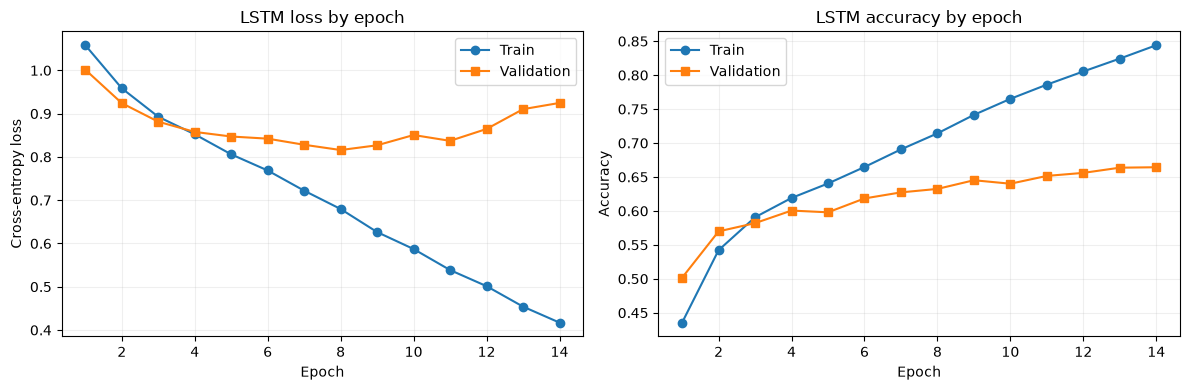

In [14]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
epochs=np.arange(1,len(history['train_loss'])+1)
axes[0].plot(epochs,history['train_loss'],'o-',label='Train'); axes[0].plot(epochs,history['val_loss'],'s-',label='Validation')
axes[0].set(title='LSTM loss by epoch',xlabel='Epoch',ylabel='Cross-entropy loss'); axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].plot(epochs,history['train_accuracy'],'o-',label='Train'); axes[1].plot(epochs,history['val_accuracy'],'s-',label='Validation')
axes[1].set(title='LSTM accuracy by epoch',xlabel='Epoch',ylabel='Accuracy'); axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.savefig('bangla_training_curves.png',dpi=160); plt.show()

## 5. Test accuracy, precision, recall, F1-score and confusion matrix

Test accuracy  : 0.6324
Macro precision: 0.5922
Macro recall   : 0.5903
Macro F1-score : 0.5864

Per-class results:
              precision    recall  f1-score   support

     Neutral       0.43      0.31      0.36       361
    Positive       0.71      0.69      0.70       654
    Negative       0.64      0.76      0.70       571

    accuracy                           0.63      1586
   macro avg       0.59      0.59      0.59      1586
weighted avg       0.62      0.63      0.62      1586



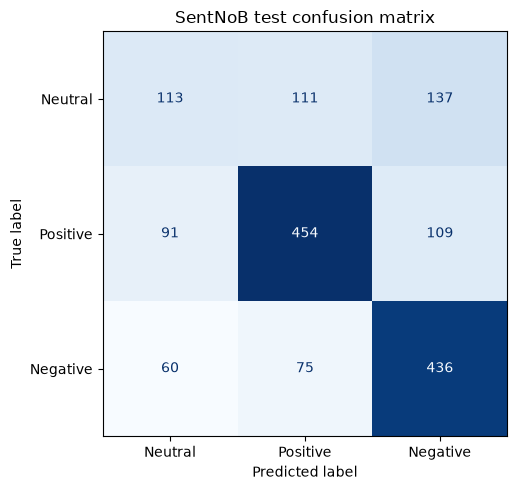

Saved: bangla_metrics.json


In [15]:
test_loss,test_accuracy,y_true,y_pred=evaluate(model,test_loader,criterion)
precision,recall,f1,_=precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
print(f'Test accuracy  : {test_accuracy:.4f}')
print(f'Macro precision: {precision:.4f}')
print(f'Macro recall   : {recall:.4f}')
print(f'Macro F1-score : {f1:.4f}')
print('\nPer-class results:')
print(classification_report(y_true,y_pred,labels=[0,1,2],target_names=['Neutral','Positive','Negative'],zero_division=0))
cm=confusion_matrix(y_true,y_pred,labels=[0,1,2])
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=['Neutral','Positive','Negative']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('SentNoB test confusion matrix'); plt.tight_layout()
plt.savefig('bangla_confusion_matrix.png',dpi=160); plt.show()
with open('bangla_metrics.json','w') as f:
    json.dump({'dataset':'SentNoB','accuracy':test_accuracy,'macro_precision':precision,'macro_recall':recall,'macro_f1':f1,'train_n':len(train_df),'val_n':len(val_df),'test_n':len(test_df)},f,indent=2)
print('Saved: bangla_metrics.json')

## 6. Predict own Bangla sentences

In [16]:
LABEL_NAMES={0:'Neutral',1:'Positive',2:'Negative'}
@torch.no_grad()
def predict_sentiment(text):
    model.eval()
    tensor=torch.tensor([encode(text)],dtype=torch.long,device=DEVICE)
    logits=model(tensor,torch.tensor([tensor.size(1)]))
    probs=torch.softmax(logits,dim=1)[0].cpu().numpy()
    result=int(probs.argmax())
    return {'sentence':text,'prediction':LABEL_NAMES[result],'confidence':round(float(probs[result]),3)}

my_sentences=[
    'আজকের খাবারটি অনেক সুস্বাদু ছিল, আমার খুব ভালো লেগেছে।',
    'এই পণ্যটির মান খুব খারাপ, আমি হতাশ।',
    'আজ বিকেলে আমাদের ক্লাস আছে।',
    'সেবাটি অসাধারণ, সবাইকে ধন্যবাদ।',
    'এত দেরিতে ডেলিভারি এসেছে যে আমি বিরক্ত।'
]
display(pd.DataFrame([predict_sentiment(x) for x in my_sentences]))
# Optional: uncomment the next line in Colab to type your own sentence
# print(predict_sentiment(input('আপনার বাংলা বাক্য লিখুন: ')))

,sentence,prediction,confidence
0,"আজকের খাবারটি অনেক সুস্বাদু ছিল, আমার খুব ভালো...",Positive,0.983
1,"এই পণ্যটির মান খুব খারাপ, আমি হতাশ।",Negative,0.528
2,আজ বিকেলে আমাদের ক্লাস আছে।,Positive,0.625
3,"সেবাটি অসাধারণ, সবাইকে ধন্যবাদ।",Positive,0.958
4,এত দেরিতে ডেলিভারি এসেছে যে আমি বিরক্ত।,Negative,0.565


### Conclusion / short note
This LSTM starts from randomly initialized weights. Word embeddings, gate parameters, and the output classifier are all trained on SentNoB. The confusion matrix shows which sentiment classes are confused most often. Word-level models can struggle with dialects, sarcasm, ambiguous comments and unknown words.
